# House Prices

##  Import & nạp dữ liệu

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid')

train = pd.read_csv('../Data/train.csv')
test  = pd.read_csv('../Data/test.csv')

train_raw = train.copy()
test_raw  = test.copy()

print('Train:', train.shape, '| Test:', test.shape)

Train: (1460, 81) | Test: (1459, 80)


## 1. Phân loại biến

In [2]:
ID_COL = 'Id'
TARGET = 'SalePrice'

discrete_cols = [
    'YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'MoSold', 'YrSold',
    'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath',
    'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageCars',
]

continuous_cols = [
    'LotFrontage', 'LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2',
    'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF',
    'GrLivArea', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch',
    '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', TARGET,
]

ordinal_cols = [
    'OverallQual', 'OverallCond', 'ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond',
    'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'HeatingQC', 'KitchenQual',
    'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC', 'Fence', 'LotShape',
    'LandSlope', 'Utilities', 'Functional', 'GarageFinish', 'PavedDrive',
]

assigned = {ID_COL, *discrete_cols, *continuous_cols, *ordinal_cols}
nominal_cols = [c for c in train.columns if c not in assigned]

groups = {
    'Số – rời rạc': discrete_cols,
    'Số – liên tục': continuous_cols,
    'Phân loại – thứ tự': ordinal_cols,
    'Phân loại – danh nghĩa': nominal_cols,
}

all_assigned = [ID_COL] + discrete_cols + continuous_cols + ordinal_cols + nominal_cols
assert len(all_assigned) == len(set(all_assigned)), 'Có cột bị gán trùng nhóm'
assert set(all_assigned) == set(train.columns), 'Có cột chưa được phân nhóm'

col2group = {ID_COL: 'Định danh (Id)'}
for g, cols in groups.items():
    for c in cols:
        col2group[c] = g

for g, cols in groups.items():
    print(f'\n[{g}] ({len(cols)} cột):\n  ', ', '.join(cols))


[Số – rời rạc] (14 cột):
   YearBuilt, YearRemodAdd, GarageYrBlt, MoSold, YrSold, BsmtFullBath, BsmtHalfBath, FullBath, HalfBath, BedroomAbvGr, KitchenAbvGr, TotRmsAbvGrd, Fireplaces, GarageCars

[Số – liên tục] (20 cột):
   LotFrontage, LotArea, MasVnrArea, BsmtFinSF1, BsmtFinSF2, BsmtUnfSF, TotalBsmtSF, 1stFlrSF, 2ndFlrSF, LowQualFinSF, GrLivArea, GarageArea, WoodDeckSF, OpenPorchSF, EnclosedPorch, 3SsnPorch, ScreenPorch, PoolArea, MiscVal, SalePrice

[Phân loại – thứ tự] (22 cột):
   OverallQual, OverallCond, ExterQual, ExterCond, BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1, BsmtFinType2, HeatingQC, KitchenQual, FireplaceQu, GarageQual, GarageCond, PoolQC, Fence, LotShape, LandSlope, Utilities, Functional, GarageFinish, PavedDrive

[Phân loại – danh nghĩa] (24 cột):
   MSSubClass, MSZoning, Street, Alley, LandContour, LotConfig, Neighborhood, Condition1, Condition2, BldgType, HouseStyle, RoofStyle, RoofMatl, Exterior1st, Exterior2nd, MasVnrType, Foundation, Heating, CentralAir, 

## 2. Báo cáo tỷ lệ dữ liệu khuyết

In [3]:
def missing_report(df, name):
    n = len(df)
    rep = pd.DataFrame({'Số dòng khuyết': df.isnull().sum()})
    rep['Tỷ lệ khuyết (%)'] = (rep['Số dòng khuyết'] / n * 100).round(2)
    rep = rep[rep['Số dòng khuyết'] > 0].sort_values('Tỷ lệ khuyết (%)', ascending=False)
    total = df.size
    print(f'[{name}] {len(rep)}/{df.shape[1]} cột có khuyết | '
          f'{int(df.isnull().sum().sum())} ô khuyết ({df.isnull().sum().sum()/total*100:.2f}% tổng số ô)')
    return rep

report_train = missing_report(train_raw, 'TRAIN')

[TRAIN] 19/81 cột có khuyết | 7829 ô khuyết (6.62% tổng số ô)


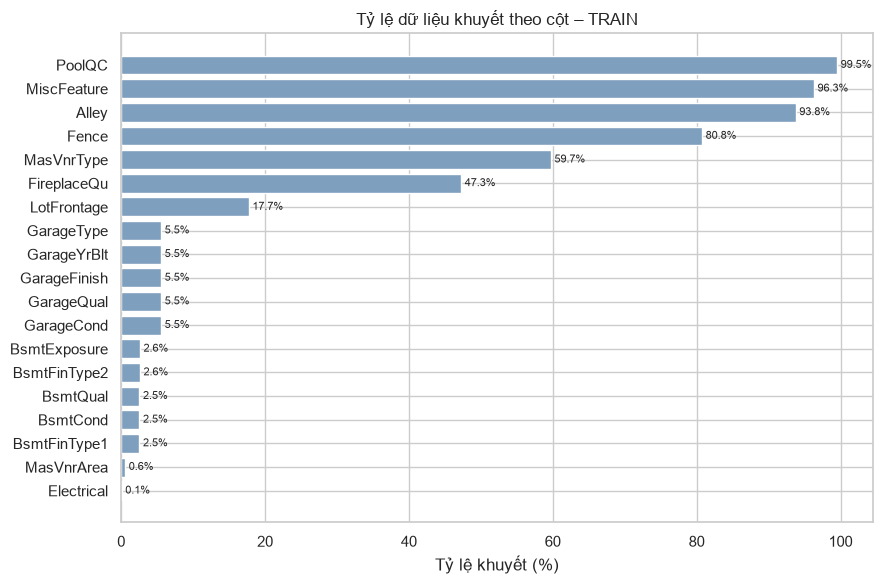

In [4]:
KEY = ['PoolQC', 'Alley', 'Fence', 'FireplaceQu']

fig, ax = plt.subplots(figsize=(9, 6))
plot_df = report_train.reset_index().rename(columns={'index': 'Cột'})
ax.barh(plot_df['Cột'], plot_df['Tỷ lệ khuyết (%)'], color='#7f9fbf')
ax.invert_yaxis()
ax.set_xlabel('Tỷ lệ khuyết (%)')
ax.set_title('Tỷ lệ dữ liệu khuyết theo cột – TRAIN')
for i, v in enumerate(plot_df['Tỷ lệ khuyết (%)']):
    ax.text(v + 0.5, i, f'{v:.1f}%', va='center', fontsize=8)
plt.tight_layout(); plt.show()

In [5]:
report_test = missing_report(test_raw, 'TEST')

[TEST] 33/80 cột có khuyết | 7878 ô khuyết (6.75% tổng số ô)


## 3. Điền khuyết

In [6]:
STRUCTURES = {
    'Hồ bơi': (['PoolQC'], ['PoolArea'],
               lambda d: d['PoolArea'].fillna(0) > 0),
    'Tầng hầm': (['BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2'],
                 ['BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath'],
                 lambda d: d['TotalBsmtSF'].fillna(0) > 0),
    'Gara': (['GarageType', 'GarageFinish', 'GarageQual', 'GarageCond'],
             ['GarageCars', 'GarageArea', 'GarageYrBlt'],
             lambda d: d['GarageType'].notna() | (d['GarageArea'].fillna(0) > 0)),
    'Lò sưởi': (['FireplaceQu'], [],
                lambda d: d['Fireplaces'].fillna(0) > 0),
    'Ốp gạch/đá': ([], ['MasVnrArea'],
                   lambda d: d['MasVnrArea'].fillna(0) > 0),
    'Tiện ích khác': (['MiscFeature'], [],
                      lambda d: d['MiscVal'].fillna(0) > 0),
}

ALWAYS_NONE = ['Alley', 'Fence', 'MasVnrType']

def fit_fill_values(ref):
    vals = {}
    for name, (cat, num, has) in STRUCTURES.items():
        mask = has(ref)
        for c in cat:
            s = ref.loc[mask, c].dropna()
            vals[c] = s.mode()[0] if len(s) else 'None'
        for c in num:
            s = ref.loc[mask, c].dropna()
            vals[c] = s.median() if len(s) else 0
    return vals

fill_values = fit_fill_values(train_raw)

def impute_structural(df):
    df = df.copy()
    masks = {name: has(df) for name, (_, _, has) in STRUCTURES.items()}
    for name, (cat, num, _) in STRUCTURES.items():
        present = masks[name]
        for c in cat:
            na = df[c].isna()
            df.loc[na & ~present, c] = 'None'
            df.loc[na & present, c] = fill_values[c]
        for c in num:
            na = df[c].isna()
            df.loc[na & ~present, c] = 0
            if c == 'GarageYrBlt':
                df.loc[na & present, c] = df.loc[na & present, 'YearBuilt']
            else:
                df.loc[na & present, c] = fill_values[c]
    for c in ALWAYS_NONE:
        df[c] = df[c].fillna('None')
    return df

train = impute_structural(train)
test = impute_structural(test)

### Khuyết ngẫu nhiên còn lại

In [7]:
RANDOM_CAT = ['Electrical', 'MSZoning', 'Utilities', 'Functional', 'Exterior1st',
              'Exterior2nd', 'KitchenQual', 'SaleType']

for c in RANDOM_CAT:
    mode_val = train_raw[c].mode()[0]
    for d in (train, test):
        d[c] = d[c].fillna(mode_val)

for d, nm in ((train, 'train'), (test, 'test')):
    for c in d.columns:
        if c in ('LotFrontage', TARGET) or not d[c].isna().any():
            continue
        fill = train_raw[c].median() if pd.api.types.is_numeric_dtype(d[c]) else train_raw[c].mode()[0]
        print(f'[safety-net] {nm}.{c}: {d[c].isna().sum()} ô → {fill}')
        d[c] = d[c].fillna(fill)

print('Còn khuyết sau bước này:')
print('  train:', train.drop(columns='LotFrontage').isna().sum().sum(),
      '| test:', test.drop(columns='LotFrontage').isna().sum().sum())

Còn khuyết sau bước này:
  train: 0 | test: 0


## 4. Nội suy LotFrontage theo Neighborhood

In [8]:
lf_median_by_nb = train_raw.groupby('Neighborhood')['LotFrontage'].median()
lf_global_median = train_raw['LotFrontage'].median()

def impute_lotfrontage(df):
    df = df.copy()
    before = int(df['LotFrontage'].isna().sum())
    df['LotFrontage'] = df['LotFrontage'].fillna(df['Neighborhood'].map(lf_median_by_nb))
    fallback = int(df['LotFrontage'].isna().sum())
    df['LotFrontage'] = df['LotFrontage'].fillna(lf_global_median)
    print(f'  khuyết ban đầu: {before} | điền theo Neighborhood: {before - fallback} | '
          f'dự phòng bằng median toàn cục: {fallback}')
    return df

print('TRAIN'); train = impute_lotfrontage(train)
print('TEST');  test  = impute_lotfrontage(test)

print(f"\nLotFrontage train – trước: mean={train_raw['LotFrontage'].mean():.2f}, "
      f"median={train_raw['LotFrontage'].median():.2f} | sau: mean={train['LotFrontage'].mean():.2f}, "
      f"median={train['LotFrontage'].median():.2f}")

TRAIN
  khuyết ban đầu: 259 | điền theo Neighborhood: 259 | dự phòng bằng median toàn cục: 0
TEST
  khuyết ban đầu: 227 | điền theo Neighborhood: 227 | dự phòng bằng median toàn cục: 0

LotFrontage train – trước: mean=70.05, median=69.00 | sau: mean=70.20, median=70.00


## 5. Kiểm tra đầu ra

In [9]:
na_train, na_test = int(train.isna().sum().sum()), int(test.isna().sum().sum())
print(f'NaN train: {na_train} | NaN test: {na_test}')
print(f'Shape train: {train.shape} | test: {test.shape}')
assert na_train == 0 and na_test == 0
assert train.shape == train_raw.shape and test.shape == test_raw.shape
assert (train['Id'].values == train_raw['Id'].values).all()

NaN train: 0 | NaN test: 0
Shape train: (1460, 81) | test: (1459, 80)


In [10]:
train.to_csv('../Data/train_filled.csv', index=False)
test.to_csv('../Data/test_filled.csv', index=False)

chk_tr = pd.read_csv('../Data/train_filled.csv', keep_default_na=False, na_values=[''])
chk_te = pd.read_csv('../Data/test_filled.csv',  keep_default_na=False, na_values=[''])
print('Nạp lại → NaN train:', chk_tr.isna().sum().sum(), '| NaN test:', chk_te.isna().sum().sum())

Nạp lại → NaN train: 0 | NaN test: 0


## 6. Feature Engineering

In [11]:
train_fe, test_fe = train.copy(), test.copy()

def add_features(d):
    d['TotalSF']      = d['TotalBsmtSF'] + d['1stFlrSF'] + d['2ndFlrSF']
    d['HouseAge']     = d['YrSold'] - d['YearBuilt']
    d['RemodAge']     = d['YrSold'] - d['YearRemodAdd']
    d['TotalBath']    = d['FullBath'] + 0.5 * d['HalfBath'] + d['BsmtFullBath'] + 0.5 * d['BsmtHalfBath']
    d['HasGarage']    = (d['GarageArea'] > 0).astype(int)
    d['HasBsmt']      = (d['TotalBsmtSF'] > 0).astype(int)
    d['HasFireplace'] = (d['Fireplaces'] > 0).astype(int)
    d['Has2ndFloor']  = (d['2ndFlrSF'] > 0).astype(int)
    d['TotalPorchSF'] = (d['OpenPorchSF'] + d['3SsnPorch'] + d['EnclosedPorch']
                         + d['ScreenPorch'] + d['WoodDeckSF'])
    return d

train_fe, test_fe = add_features(train_fe), add_features(test_fe)

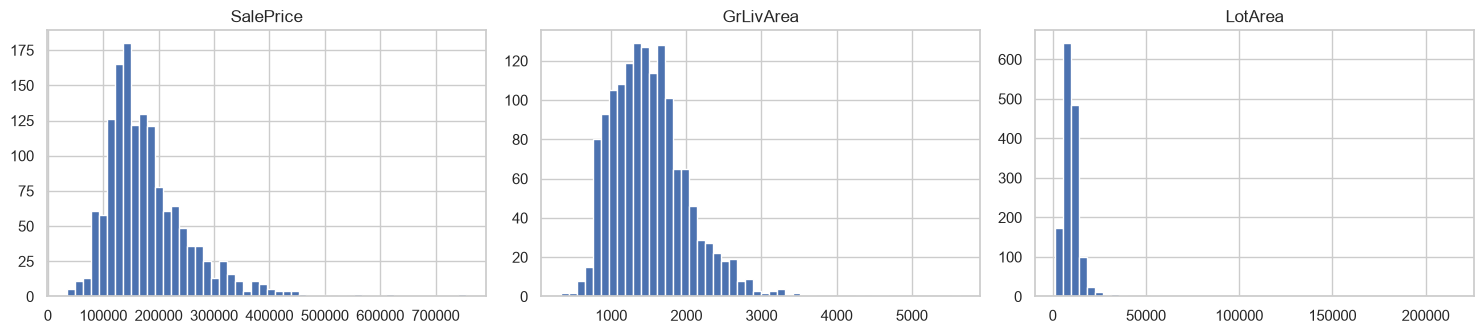

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, ['SalePrice', 'GrLivArea', 'LotArea']):
    train_fe[col].hist(bins=50, ax=ax); ax.set_title(col)
plt.tight_layout(); plt.show()

In [13]:
log_features = ['MiscVal', 'PoolArea', 'LotArea', '3SsnPorch', 'LowQualFinSF', 'BsmtFinSF2',
                'ScreenPorch', 'EnclosedPorch', 'MasVnrArea', 'LotFrontage', 'OpenPorchSF',
                'BsmtFinSF1', 'WoodDeckSF', 'TotalBsmtSF', '1stFlrSF', 'GrLivArea', 'TotalSF']

for col in log_features:
    train_fe[col] = np.log1p(train_fe[col])
    test_fe[col]  = np.log1p(test_fe[col])

In [14]:
print('Cột chỉ có ở train:', set(train_fe.columns) - set(test_fe.columns))
print('Cột chỉ có ở test :', set(test_fe.columns) - set(train_fe.columns))
print('Train shape:', train_fe.shape, '| Test shape:', test_fe.shape)
print('NaN train_fe:', train_fe.isna().sum().sum(), '| NaN test_fe:', test_fe.isna().sum().sum())
assert train_fe.isna().sum().sum() == 0 and test_fe.isna().sum().sum() == 0

train_fe.to_csv('../Data/train_fe.csv', index=False)
test_fe.to_csv('../Data/test_fe.csv', index=False)

Cột chỉ có ở train: {'SalePrice'}
Cột chỉ có ở test : set()
Train shape: (1460, 90) | Test shape: (1459, 89)
NaN train_fe: 0 | NaN test_fe: 0
